# 01 Daten, Modell und Probelauf

Ziel dieses Notebooks: MNIST laden und aufteilen, das MLP bauen und einen ersten Trainingslauf ohne Shuffling (Variante A) machen. Danach prüfen wir, ob zwei Läufe mit gleichem Seed identisch sind.

In [1]:
import time

import matplotlib.pyplot as plt
import torch

from batch_shuffling_regularization.data import load_mnist
from batch_shuffling_regularization.model import build_mlp
from batch_shuffling_regularization.shuffling import no_shuffle
from batch_shuffling_regularization.training import TrainConfig, device_name, get_device, make_deterministic, train

make_deterministic()
device = get_device()
print(torch.__version__, device_name(device))

2.11.0+cu128 NVIDIA GeForce RTX 5070 Ti


## Daten

60.000 Trainingsbilder werden in 50.000 Train und 10.000 Validation geteilt. 10.000 Testbilder bleiben unberührt und dienen nur zum Berichten. Train behält die Original-Reihenfolge von MNIST.

In [2]:
data = load_mnist(device)
for name, split in [("train", data.train), ("val", data.val), ("test", data.test)]:
    print(f"{name:5s} x={tuple(split.x.shape)}  Bilder pro Klasse: {split.y.bincount().tolist()}")

train x=(50000, 784)  Bilder pro Klasse: [4970, 5575, 4940, 5065, 4875, 4500, 4998, 5220, 4920, 4937]
val   x=(10000, 784)  Bilder pro Klasse: [953, 1167, 1018, 1066, 967, 921, 920, 1045, 931, 1012]
test  x=(10000, 784)  Bilder pro Klasse: [980, 1135, 1032, 1010, 982, 892, 958, 1028, 974, 1009]


Die Original-Reihenfolge ist nicht nach Klassen sortiert. Die ersten 30 Labels:

In [3]:
print(data.train.y[:30].tolist())

[5, 4, 9, 2, 1, 3, 1, 4, 3, 5, 3, 6, 1, 7, 2, 8, 6, 9, 4, 0, 9, 1, 1, 2, 4, 3, 2, 7, 3, 8]


## Modell

Fully connected: 784 -> 256 -> 256 -> 10, ReLU, keine Regularisierung.

In [4]:
model = build_mlp(seed=0, device=device)
print(model)
print("Parameter:", sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Linear(in_features=784, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=256, bias=True)
  (3): ReLU()
  (4): Linear(in_features=256, out_features=10, bias=True)
)
Parameter: 269322


## Probelauf: Variante A

Plain SGD, heißt kein Momentum. Config:

In [5]:
cfg = TrainConfig()
print(cfg)

TrainConfig(epochs=30, batch_size=100, lr=0.1)


In [6]:
start = time.perf_counter()
history = train(model, data, no_shuffle, cfg, order_seed=0)
print(f"Dauer: {time.perf_counter() - start:.1f} s")
history.round(4)

Dauer: 10.8 s


,train_loss,train_acc,val_loss,val_acc,test_loss,test_acc
epoch,,,,,,
0,2.3136,0.0971,2.3139,0.1001,2.3158,0.0995
1,0.1881,0.9395,0.2048,0.9376,0.1904,0.9403
2,0.1089,0.9661,0.1365,0.9589,0.1229,0.9606
3,0.0719,0.9783,0.1086,0.9664,0.0961,0.9699
4,0.0545,0.9839,0.0980,0.9690,0.0867,0.9726
5,0.0410,0.9881,0.0894,0.9729,0.0809,0.9743
6,0.0325,0.9906,0.0855,0.9744,0.0784,0.9760
7,0.0264,0.9923,0.0847,0.9752,0.0788,0.9759
8,0.0215,0.9933,0.0845,0.9752,0.0791,0.9762


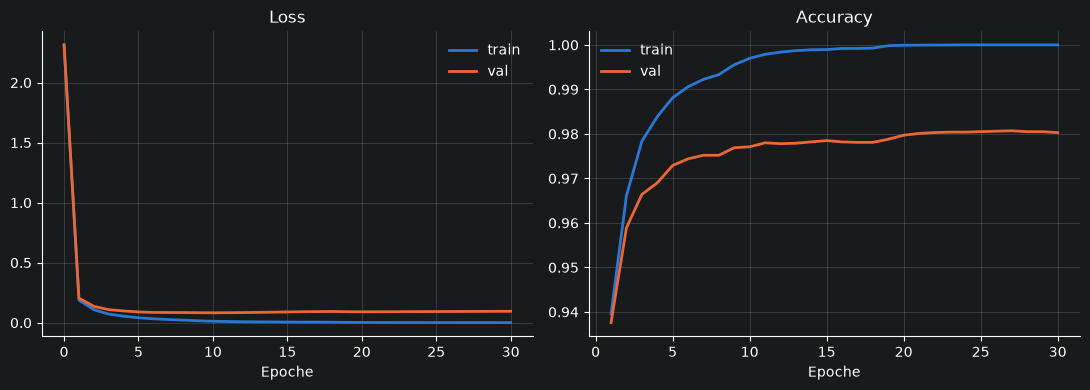

In [7]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 4))
colors = {"train": "#2a78d6", "val": "#eb6834"}
for name, color in colors.items():
    ax_loss.plot(history.index, history[f"{name}_loss"], color=color, lw=2, label=name)
    ax_acc.plot(history.index[1:], history[f"{name}_acc"].iloc[1:], color=color, lw=2, label=name)
ax_loss.set(title="Loss", xlabel="Epoche")
ax_acc.set(title="Accuracy", xlabel="Epoche")
for ax in (ax_loss, ax_acc):
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
plt.tight_layout()

In [8]:
best = history["val_acc"].idxmax()
print(f"Beste Val-Accuracy {history.loc[best, 'val_acc']:.4f} in Epoche {best}, "
      f"Test-Accuracy dort {history.loc[best, 'test_acc']:.4f}")
print(f"Generalization Gap (Val-Loss - Train-Loss) in der letzten Epoche: "
      f"{history['val_loss'].iloc[-1] - history['train_loss'].iloc[-1]:.4f}")

Beste Val-Accuracy 0.9807 in Epoche 27, Test-Accuracy dort 0.9799
Generalization Gap (Val-Loss - Train-Loss) in der letzten Epoche: 0.0943


## Reproduzierbarkeit

Zwei kurze Läufe mit identischem Seed müssen exakt dieselben Zahlen liefern, sonst können wir Unterschiede zwischen Varianten nicht sauber zuordnen.

In [9]:
short = TrainConfig(epochs=3)
run_1 = train(build_mlp(seed=0, device=device), data, no_shuffle, short, order_seed=0)
run_2 = train(build_mlp(seed=0, device=device), data, no_shuffle, short, order_seed=0)
print("identisch:", run_1.equals(run_2))

identisch: True
